In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move_special import *
import pygame

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/phd/pytorch_DGN/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [2]:
from plot_utils_and_functions import *

In [3]:
n = 300
Lx = 32
Ly = 32
eta = 0.01
decay_rate = 0.015
beta = 4.5
delta = 0.3
n_special = 30
t_transient = 200
tmax = 1200
eta_special = 1
beta_special = 4.5
delta_special = 0.3

In [4]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0_prime = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)
s0 = (n*eta)/(decay_rate*Lx**2)

In [5]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

In [ ]:
import os
import numpy as np

T = 2200
n_sim = 10
n_agents = n + n_special
n_steps = T - t_transient
os.makedirs(output_dir, exist_ok=True)

for sim in range(n_sim):
    print(f"Simulation {sim + 1}/{n_sim}")

    # Allocazione per singola simulazione (stessa struttura del primo script)
    positions = np.zeros((n_steps, len(beta_list), len(delta_list), n_agents, 2), dtype=np.float32)
    pheromones = np.zeros((n_steps, len(beta_list), len(delta_list), Lx, Ly), dtype=np.float32)
    op_s_results = np.zeros((n_steps, len(beta_list), len(delta_list)), dtype=np.float32)
    op_p_results = np.zeros((n_steps, len(beta_list), len(delta_list)), dtype=np.float32)
    global_reward4_results = np.zeros((n_steps, len(beta_list), len(delta_list)), dtype=np.float32)

    for b_idx, beta in enumerate(beta_list):
        for d_idx, delta in enumerate(delta_list):
            print(f"Sim {sim + 1}/{n_sim} - Testing with delta = {delta}, beta = {beta}")

            env = Ants_move_special(
                n,
                Lx,
                Ly,
                delta,
                beta,
                decay_rate,
                eta,
                eta_special,
                beta,
                delta,
                tmax,
                n_special,
                t_transient,
            )

            env.reset_objects()
            env.transient()

            for t in range(n_steps):
                env.update()
                positions[t, b_idx, d_idx, :, :] = env.positions
                pheromones[t, b_idx, d_idx, :, :] = env.pheromones

                # 1. Calcolo parametri d'ordine al tempo t (evitando il ricalcolo finale)
                rho_t = compute_density(env.positions, Lx, Ly, n)
                s_t = order_parameter_s(env.pheromones, Lx * Ly)
                p_t = order_parameter_p(env.pheromones, rho_t)

                op_s_results[t, b_idx, d_idx] = s_t
                op_p_results[t, b_idx, d_idx] = p_t

                # 2. Metriche del grafo per le componenti connesse
                metrics_for_components = global_reward(env)
                n_edges = metrics_for_components[:, 0]
                n_nodes = metrics_for_components[:, 1]
                num_components = len(metrics_for_components)

                # 3. Calcolo vettoriale di edge_pen
                edge_pen = np.divide(
                    -n_edges,
                    n_nodes - 1,
                    out=np.zeros_like(n_edges, dtype=float),
                    where=(n_nodes > 1),
                )

                # 4. Calcolo di reward4
                global_reward4_results[t, b_idx, d_idx] = np.sum(edge_pen) + 0.5 * num_components * (
                    s_t * min(env.Lx, np.mean(n_nodes)) / env.Lx + p_t
                )

                if t == tmax - t_transient:
                    # Azzeramento feromone per le formiche speciali
                    env.amount[n:] = 0

    np.savez_compressed(
        os.path.join(f"results_sim_enh_{sim}.npz"),
        positions=positions,
        pheromones=pheromones,
        op_s=op_s_results,
        op_p=op_p_results,
        reward4=global_reward4_results,
        beta_list=np.array(beta_list),
        delta_list=np.array(delta_list),
    )

Testing with delta = 0.3, beta = 3.5
Testing with delta = 0.4, beta = 3.5
Testing with delta = 0.5, beta = 3.5
Testing with delta = 0.6, beta = 3.5
Testing with delta = 0.7, beta = 3.5
Testing with delta = 0.8, beta = 3.5
Testing with delta = 0.3, beta = 4.5
Testing with delta = 0.4, beta = 4.5
Testing with delta = 0.5, beta = 4.5
Testing with delta = 0.6, beta = 4.5
Testing with delta = 0.7, beta = 4.5
Testing with delta = 0.8, beta = 4.5
Testing with delta = 0.3, beta = 5.5
Testing with delta = 0.4, beta = 5.5
Testing with delta = 0.5, beta = 5.5
Testing with delta = 0.6, beta = 5.5
Testing with delta = 0.7, beta = 5.5
Testing with delta = 0.8, beta = 5.5
Testing with delta = 0.3, beta = 6.5
Testing with delta = 0.4, beta = 6.5
Testing with delta = 0.5, beta = 6.5
Testing with delta = 0.6, beta = 6.5
Testing with delta = 0.7, beta = 6.5
Testing with delta = 0.8, beta = 6.5
Testing with delta = 0.3, beta = 7.5
Testing with delta = 0.4, beta = 7.5
Testing with delta = 0.5, beta = 7.5
T

In [7]:
# save the results
np.savez(f"results_withdrawal_total.npz",
         op_s_results=op_s_results,
         op_p_results=op_p_results,
         global_reward4_results=global_reward4_results
)

In [6]:
load = True
if load:
    results = np.load("results_withdrawal_total.npz")
    op_s_results = results['op_s_results']
    op_p_results = results['op_p_results']
    global_reward4_results = results['global_reward4_results']

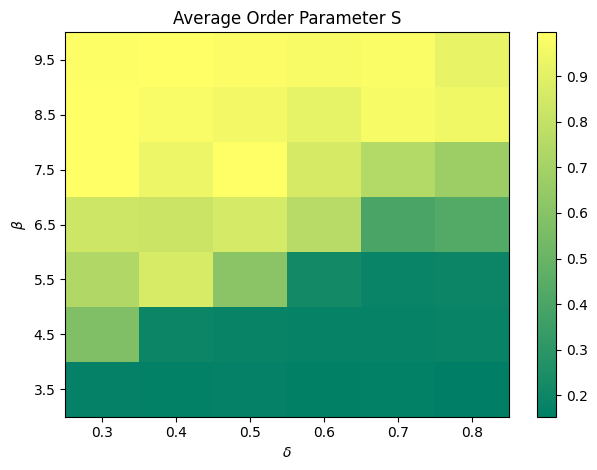

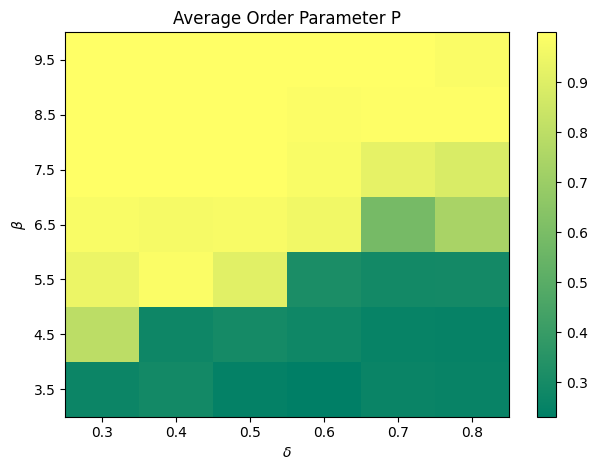

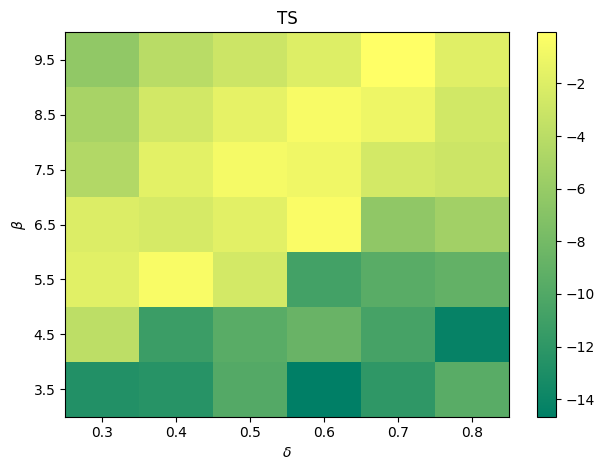

In [7]:
# explore the results in a heatmap
op_s_avg = op_s_results[:,-50:,:,:].mean(axis=(0,1))
plot_heatmap(op_s_avg, delta_list, beta_list, cmap='summer', title='Average Order Parameter S')
op_p_avg = op_p_results[:,-50:,:,:].mean(axis=(0,1))
plot_heatmap(op_p_avg, delta_list, beta_list, cmap='summer', title='Average Order Parameter P')
global_reward4_avg = global_reward4_results[:,-50:,:,:].mean(axis=(0,1))
plot_heatmap(global_reward4_avg, delta_list, beta_list, cmap='summer', title='TS')

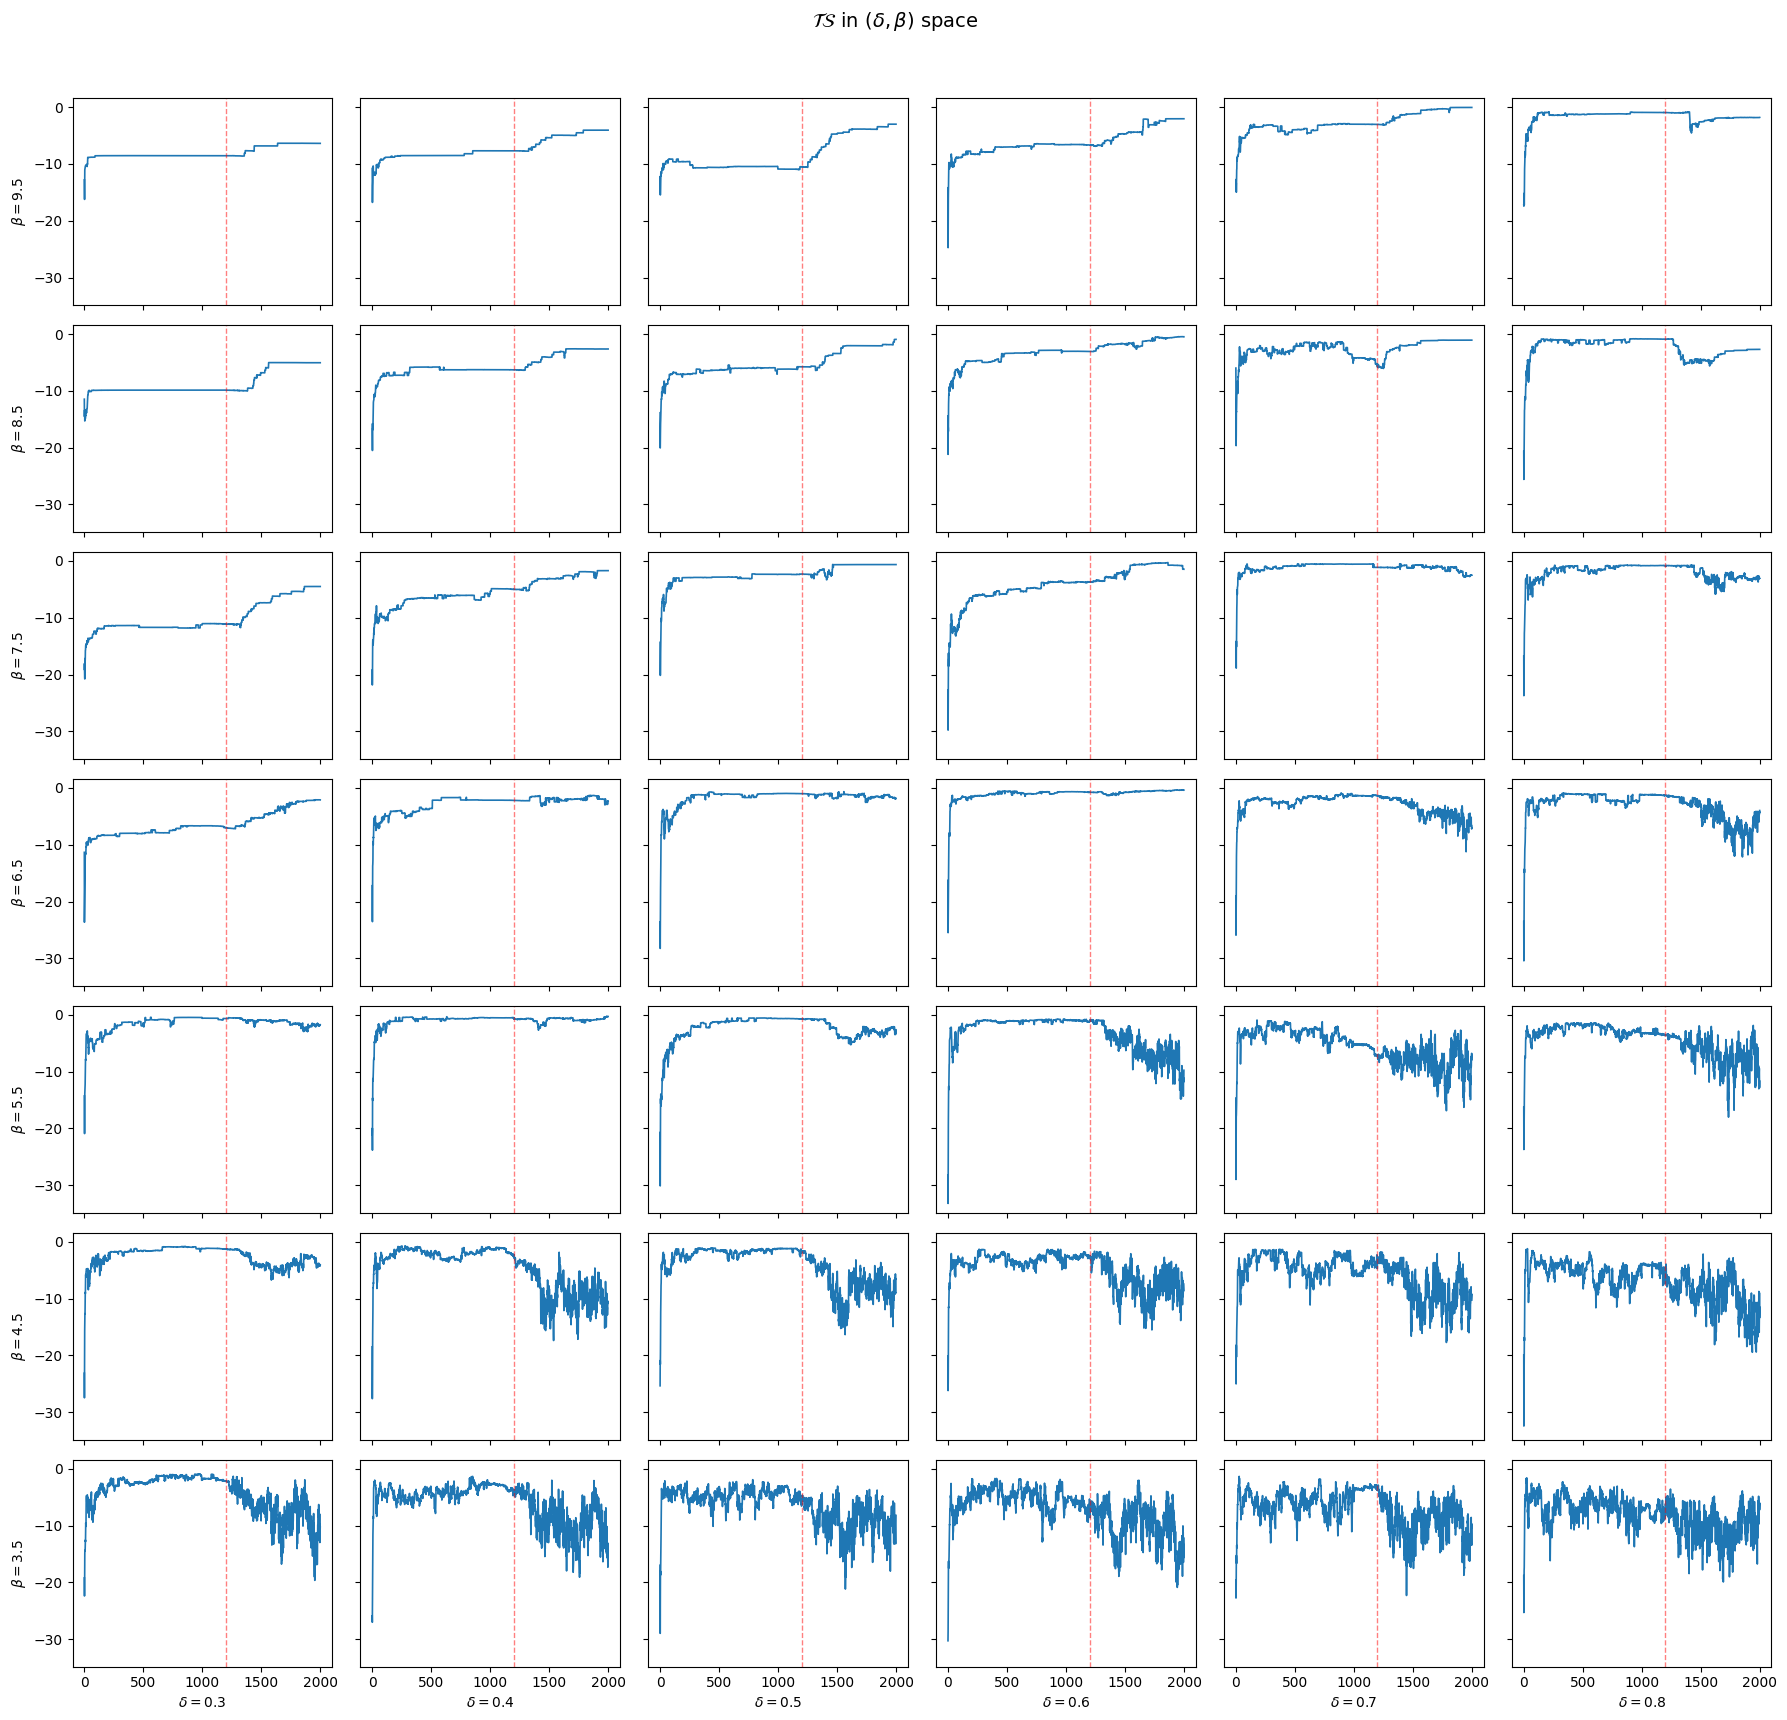

In [18]:
beta_arr = np.asarray(beta_list)
delta_arr = np.asarray(delta_list)

# Media (e deviazione standard) sulle simulazioni lungo l'asse 0 -> shape (2000, n_beta, n_delta)
n_sim = global_reward4_results.shape[0]
ts_mean = np.mean(global_reward4_results, axis=0)
ts_std = np.std(global_reward4_results, axis=0) if n_sim > 1 else None

# Indici ordinati in senso crescente per rispettare l'orientamento degli assi
beta_sorted_idx = np.argsort(beta_arr)
delta_sorted_idx = np.argsort(delta_arr)

n_beta = len(beta_arr)
n_delta = len(delta_arr)

fig, axes = plt.subplots(
    nrows=n_beta,
    ncols=n_delta,
    figsize=(3 * n_delta, 2.5 * n_beta),
    sharex=True,
    sharey=True,
    squeeze=False
)

t = np.arange(ts_mean.shape[0])

for row in range(n_beta):
    # row=0 corrisponde al beta massimo (in alto), row=n_beta-1 al beta minimo (in basso)
    b_idx = beta_sorted_idx[n_beta - 1 - row]
    beta_val = beta_arr[b_idx]

    for col in range(n_delta):
        d_idx = delta_sorted_idx[col]
        delta_val = delta_arr[d_idx]

        ax = axes[row, col]
        mean_curve = ts_mean[:, b_idx, d_idx]

        ax.plot(t, mean_curve, linewidth=1.2)
        if ts_std is not None:
            std_curve = ts_std[:, b_idx, d_idx]
            ax.fill_between(t, mean_curve - std_curve, mean_curve + std_curve, alpha=0.2)

        ax.axvline(x=tmax, color='red', linestyle='--', alpha=0.5, linewidth=1)

        # Valori dei parametri sui bordi inferiori e sinistri
        if row == n_beta - 1:
            ax.set_xlabel(rf'$\delta = {delta_val}$', fontsize=10)
        if col == 0:
            ax.set_ylabel(rf'$\beta = {beta_val}$', fontsize=10)

fig.suptitle(r'$\mathcal{TS}$ in ($\delta, \beta$) space', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
pos = np.zeros((T-t_transient, n+n_special, 2))
pher = np.zeros((T-t_transient, Lx, Ly))

beta = 5.5
delta = 0.3
print(f"Testing with delta = {delta}, beta = {beta}")

env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
        beta, delta, tmax, n_special, t_transient)

env.reset_objects()
env.transient()

for t in range(T-t_transient):
    env.update()
    pos[t, :, :] = env.positions.copy()
    pher[t, :, :] = env.pheromones.copy()

    if t==tmax-t_transient:
        # Set the amount of pheromone to zero for the last n ants (the special ones)
        env.amount[n:] = 0

order_param_s = []
order_param_p = []

rhos = [compute_density(pos[i], Lx, Ly, n) for i in range(len(pos))]

for pheromones, rho in zip(pher, rhos):
    s = order_parameter_s(pheromones, Lx * Ly)
    p = order_parameter_p(pheromones, rho)
    order_param_s.append(s)
    order_param_p.append(p)

Testing with delta = 0.3, beta = 5.5


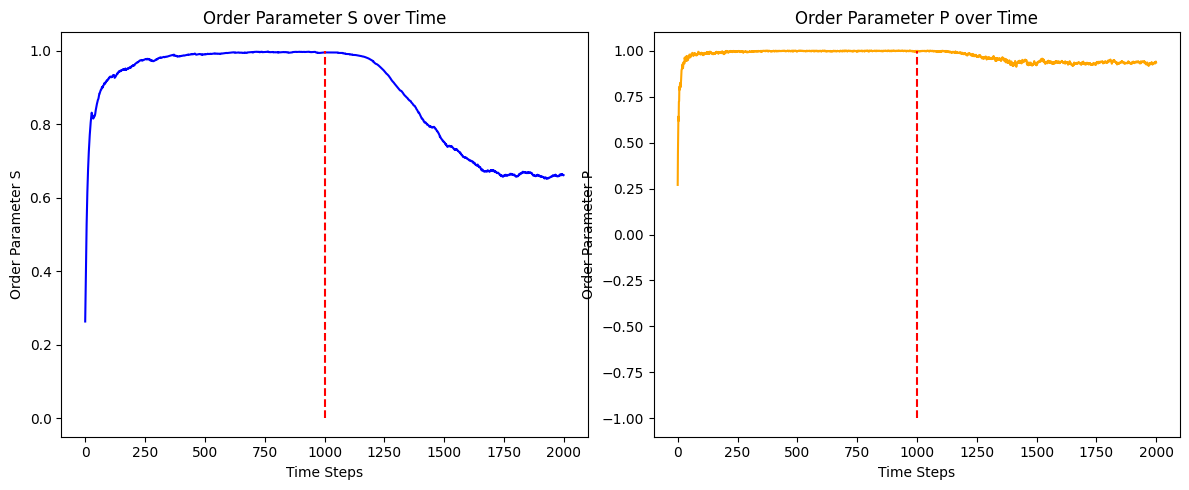

In [ ]:
order_param_s = []
order_param_p = []

rhos = [compute_density(pos[i], Lx, Ly, n) for i in range(len(pos))]

for pheromones, rho in zip(pher, rhos):
    s = order_parameter_s(pheromones, Lx * Ly)
    p = order_parameter_p(pheromones, rho)
    order_param_s.append(s)
    order_param_p.append(p)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(order_param_s, label='Order Parameter S', color='blue')
plt.title('Order Parameter S over Time')
plt.xlabel('Time Steps')
plt.ylabel('Order Parameter S')
plt.vlines(x=env.tmax-env.t_transient,
            color='red', linestyle='--', label='Withdrawal Time', ymin=0, ymax=1)
plt.subplot(1, 2, 2)
plt.plot(order_param_p, label='Order Parameter P', color='orange')
plt.title('Order Parameter P over Time')
plt.xlabel('Time Steps')
plt.ylabel('Order Parameter P')
plt.tight_layout()
plt.vlines(x=env.tmax-env.t_transient,
            color='red', linestyle='--', label='Withdrawal Time', ymin=-1, ymax=1)
plt.show()

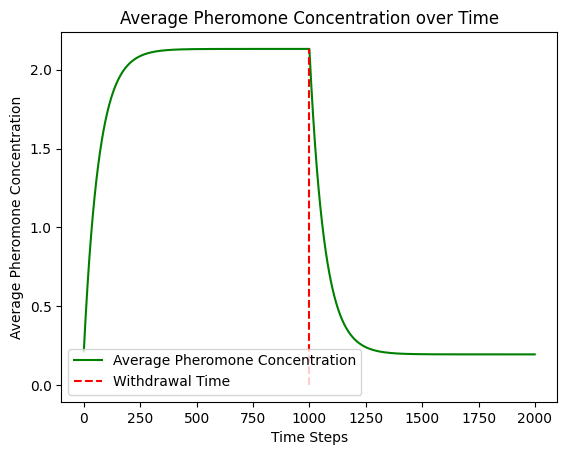

In [ ]:
plt.plot(np.mean(pher, axis=(1,2)), label='Average Pheromone Concentration', color='green')
plt.title('Average Pheromone Concentration over Time')
plt.xlabel('Time Steps')
plt.ylabel('Average Pheromone Concentration')
plt.vlines(x=env.tmax-env.t_transient,
            color='red', linestyle='--', label='Withdrawal Time', ymin=0, ymax=np.mean(pher, axis=(1,2)).max())
plt.legend()
plt.show()

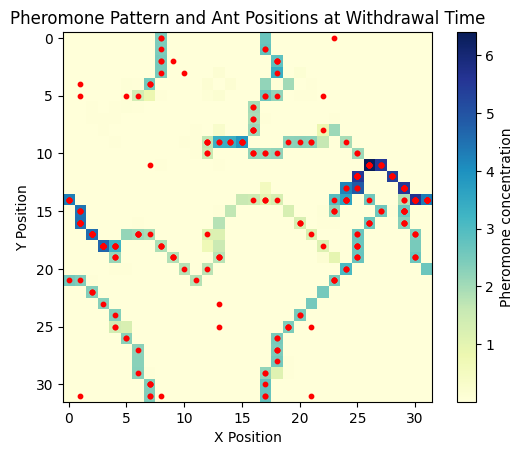

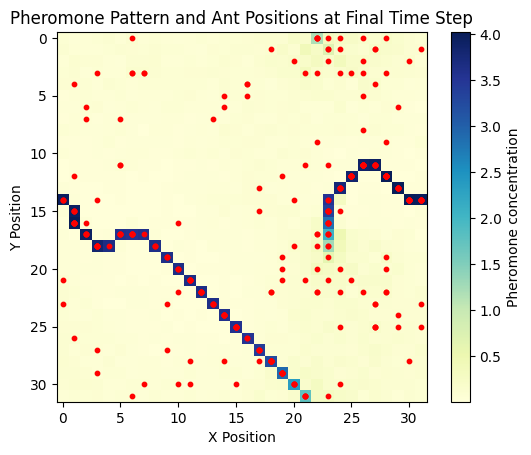

In [ ]:
plt.imshow(np.array(pher)[env.tmax], cmap='YlGnBu')
plt.colorbar(label='Pheromone concentration')
plt.scatter(np.array(pos)[env.tmax][:n, 1], np.array(pos)[env.tmax][:n, 0], c='red', s=10, label='Ant Positions')
plt.title(f'Pheromone Pattern and Ant Positions at Withdrawal Time')
plt.xlabel('X Position')
plt.ylabel('Y Position')
plt.show()

plt.imshow(np.array(pher)[-1], cmap='YlGnBu')
plt.colorbar(label='Pheromone concentration')
plt.scatter(np.array(pos)[-1][:n, 1], np.array(pos)[-1][:n, 0], c='red', s=10, label='Ant Positions')
plt.title(f'Pheromone Pattern and Ant Positions at Final Time Step')
plt.xlabel('X Position')
plt.ylabel('Y Position')
plt.show()


In [ ]:
# save the results
np.savez(f"results_withdrawal.npz",
         op_s_results=op_s_results,
         op_p_results=op_p_results,
         global_reward4_results=global_reward4_results
)